In [7]:
import tensorflow as tf
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.optimizers import Adagrad, RMSprop
from tensorflow.keras.losses import SparseCategoricalCrossentropy
from tensorflow.keras.metrics import SparseCategoricalAccuracy

In [11]:
train_data = pd.read_csv("/home/unix/fashion-mnist_train.csv")
test_data = pd.read_csv("/home/unix/fashion-mnist_test.csv")

y_train = train_data.iloc[:, 0].values
y_test = test_data.iloc[:, 0].values

x_train = train_data.iloc[:, 1:].values
x_test = test_data.iloc[:, 1:].values

x_train = x_train / 255.0
x_test = x_test / 255.0

x_train = x_train.reshape(-1, 28, 28)
x_test = x_test.reshape(-1, 28, 28)



model = Sequential([
    Flatten(input_shape=(28, 28)),
    
    Dense(256, activation='relu'),
    
    Dense(128, activation='relu'),
    
    Dense(64, activation='tanh'),
    
    Dense(10, activation='softmax')
])


In [12]:
model.compile(optimizer=RMSprop(learning_rate=0.01),
              loss=SparseCategoricalCrossentropy(),
              metrics=[SparseCategoricalAccuracy()])


history= model.fit(x_train, y_train, epochs=10, validation_data=(x_test, y_test))


test_loss, test_acc = model.evaluate(x_test, y_test)
print(f'\nTest accuracy: {test_acc}')

Epoch 1/10
1875/1875 [==============================] - 5s 2ms/step - loss: 1.4144 - sparse_categorical_accuracy: 0.3975 - val_loss: 1.4311 - val_sparse_categorical_accuracy: 0.4060
Epoch 2/10
1875/1875 [==============================] - 4s 2ms/step - loss: 1.3115 - sparse_categorical_accuracy: 0.4438 - val_loss: 1.3432 - val_sparse_categorical_accuracy: 0.4720
Epoch 3/10
1875/1875 [==============================] - 4s 2ms/step - loss: 1.2299 - sparse_categorical_accuracy: 0.4867 - val_loss: 1.2738 - val_sparse_categorical_accuracy: 0.4303
Epoch 4/10
1875/1875 [==============================] - 4s 2ms/step - loss: 1.2192 - sparse_categorical_accuracy: 0.4961 - val_loss: 1.3950 - val_sparse_categorical_accuracy: 0.4131
Epoch 5/10
1875/1875 [==============================] - 4s 2ms/step - loss: 1.1805 - sparse_categorical_accuracy: 0.5216 - val_loss: 1.1201 - val_sparse_categorical_accuracy: 0.5011
Epoch 6/10
1875/1875 [==============================] - 4s 2ms/step - loss: 1.1063 - spars

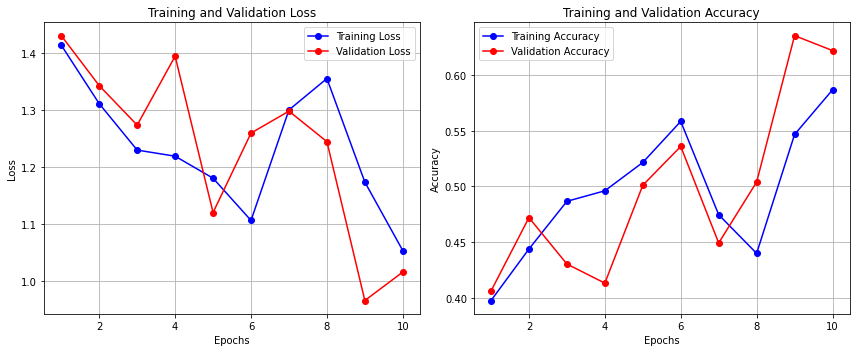

In [13]:

def plot_training_history(history):
 
    loss = history.history['loss']
    val_loss = history.history['val_loss']

    accuracy = history.history['sparse_categorical_accuracy']
    val_accuracy = history.history['val_sparse_categorical_accuracy']

    epochs = range(1, len(loss) + 1)


    plt.figure(figsize=(12, 5))

 
    plt.subplot(1, 2, 1)
    plt.plot(epochs, loss, 'bo-', label='Training Loss')
    plt.plot(epochs, val_loss, 'ro-', label='Validation Loss')
    plt.title('Training and Validation Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)

  
    plt.subplot(1, 2, 2)
    plt.plot(epochs, accuracy, 'bo-', label='Training Accuracy')
    plt.plot(epochs, val_accuracy, 'ro-', label='Validation Accuracy')
    plt.title('Training and Validation Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()



plot_training_history(history)

